# 多分类与连续值回归

按 **Shift+Enter** 从上到下逐单元运行。变量保留在当前内核中；如果修改上游参数，请重新运行其后的单元。

本教程使用固定合成数据，演示软件流程，不提供临床效能结论。需要完整仓库和对应原生安装包；实际源码版本和原生扩展身份请查看本次执行收据。

## 1. 环境与独立输出目录

确认后端为 Rust。后续每步都可以检查中间对象；示例数据生成辅助函数只负责小型输入构造。

In [1]:
from pathlib import Path
import sys, tempfile
from IPython.display import display, Image
# 从 Notebook 所在目录或仓库根目录启动均可。
REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'examples/native/_shared.py').exists()), None)
if REPO is None:
    raise RuntimeError('请先下载完整仓库，并在仓库内启动 Jupyter。')
sys.path.insert(0, str(REPO/'examples/native'))
import ov_radiomics as rad
print(rad.backend_info())
# 每次完整运行使用新目录，避免覆盖已有结果。
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-03_multiclass_regression-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
root = output
print('输出目录:', output)
import hashlib, importlib.metadata, json, platform
runtime = {'interpreter': sys.executable, 'python': platform.python_version(),
           'package_source': rad.__file__, 'backend': rad.backend_info(),
           'packages': {name: importlib.metadata.version(name) for name in
                        ('ov-radiomics', 'numpy', 'pandas', 'matplotlib', 'ipykernel')}}
from ov_radiomics._backend import try_native
extension = try_native()
if extension is None:
    raise RuntimeError('本教程需要真实 Rust 原生扩展。')
runtime['native_path'] = extension.__file__
runtime['native_sha256'] = hashlib.sha256(Path(extension.__file__).read_bytes()).hexdigest()
runtime['package_python_sha256'] = {p.relative_to(Path(rad.__file__).parent).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                                  for p in sorted(Path(rad.__file__).parent.rglob('*.py'))}
(output/'tutorial-runtime.json').write_text(json.dumps(runtime, ensure_ascii=False, indent=2), encoding='utf-8')
 
from _shared import output_arguments, provenance, task_data
import ov_radiomics as rad


{'metrics_backend': 'rust', 'rust_core_version': '0.1.0', 'schema_version': 1, 'api_revision': 2, 'native_compatible': True}
输出目录: /tmp/radiomics-doctrees-8y5ry4nj/tutorials/execution/03_multiclass_regression/artifacts


## 2. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [2]:
task = 'multiclass'
data, features, classes = task_data(task)

## 3. 配置任务对应筛选

多分类不能把类别编码直接作为连续回归目标。选择器随整个 Pipeline 在患者分组交叉验证内拟合。

In [3]:
selection = rad.FeatureSelector(task=task, backend='rust', univariate=None, lasso=False)

## 4. 执行原生分析并检查结果

阅读本单元的核心调用与参数。模型训练只使用训练队列；评价时显式保留患者单位和队列身份。

In [4]:
result = rad.train_models(data, 'target', features, task=task, classes=classes, backend='rust', selector=selection, patient_id='patient_id', cv=3, inner_cv=2)
result.save(output / task)

## 5. 阅读任务评价

二分类关注 AUC 与校准，多分类关注分类别及 macro/micro/weighted 汇总，回归关注 MAE/RMSE/R²。合成数据分数不是临床证据。

In [5]:
report = rad.evaluate(result, backend='rust', prediction_unit='patient', ci_method='bootstrap', n_bootstrap=200, random_state=20261114)
report.to_csv(output / (task + '-metrics.csv'), index=False)
result.predict(data.loc[data.group != 'train'].drop(columns='target')).dataframe.to_csv(output / (task + '-unlabeled-predictions.csv'), index=False)
print(task, report.to_string(index=False), sep='\n')
task = 'regression'
if hasattr(report, 'head'):
    display(report.head())

multiclass
model      group       task prediction_unit  n prediction_type          status  accuracy  macro_ovr_auc  weighted_ovr_auc  micro_ovr_auc  macro_average_precision  weighted_average_precision  micro_average_precision  log_loss_eps1e15  multiclass_brier_sum  macro_precision  macro_recall  macro_f1  micro_precision  micro_recall  micro_f1  weighted_precision  weighted_recall  weighted_f1   ci_low  ci_high
   LR external_A multiclass         patient  6        external prediction_only       NaN            NaN               NaN            NaN                      NaN                         NaN                      NaN               NaN                   NaN              NaN           NaN       NaN              NaN           NaN       NaN                 NaN              NaN          NaN      NaN      NaN
   LR       test multiclass         patient 12         holdout       evaluated  0.666667       0.927083          0.927083       0.881944                 0.886111                  

,model,group,task,prediction_unit,n,prediction_type,status,accuracy,macro_ovr_auc,weighted_ovr_auc,...,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_precision,weighted_recall,weighted_f1,ci_low,ci_high
0,LR,external_A,multiclass,patient,6,external,prediction_only,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LR,test,multiclass,patient,12,holdout,evaluated,0.666667,0.927083,0.927083,...,0.666667,0.655123,0.666667,0.666667,0.666667,0.746032,0.666667,0.655123,0.812240,1.000000
2,LR,train,multiclass,patient,48,apparent,evaluated,0.583333,0.763021,0.763021,...,0.583333,0.580932,0.583333,0.583333,0.583333,0.585611,0.583333,0.580932,0.671875,0.837321


## 6. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [6]:
data, features, classes = task_data(task)

## 7. 配置任务对应筛选

多分类不能把类别编码直接作为连续回归目标。选择器随整个 Pipeline 在患者分组交叉验证内拟合。

In [7]:
selection = rad.FeatureSelector(task=task, backend='rust', univariate=None, lasso=False)

## 8. 执行原生分析并检查结果

阅读本单元的核心调用与参数。模型训练只使用训练队列；评价时显式保留患者单位和队列身份。

In [8]:
result = rad.train_models(data, 'target', features, task=task, classes=classes, backend='rust', selector=selection, patient_id='patient_id', cv=3, inner_cv=2)
result.save(output / task)

## 9. 阅读任务评价

二分类关注 AUC 与校准，多分类关注分类别及 macro/micro/weighted 汇总，回归关注 MAE/RMSE/R²。合成数据分数不是临床证据。

In [9]:
report = rad.evaluate(result, backend='rust', prediction_unit='patient', ci_method='bootstrap', n_bootstrap=200, random_state=20261114)
report.to_csv(output / (task + '-metrics.csv'), index=False)
result.predict(data.loc[data.group != 'train'].drop(columns='target')).dataframe.to_csv(output / (task + '-unlabeled-predictions.csv'), index=False)
print(task, report.to_string(index=False), sep='\n')
provenance(output, '03_multiclass_regression', models=dict(multiclass='multinomial softmax LR with L2', regression='Ridge'), evaluation_unit='patient', bootstrap='200 replicates for demonstration; use predeclared study replication count')
if hasattr(report, 'head'):
    display(report.head())

regression
model      group       task prediction_unit  n prediction_type          status      mae     rmse       r2   ci_low  ci_high
Ridge external_A regression         patient  6        external prediction_only      NaN      NaN      NaN      NaN      NaN
Ridge       test regression         patient 12         holdout       evaluated 0.329347 0.452737 0.938881 0.252522 0.633718
Ridge      train regression         patient 48        apparent       evaluated 0.341879 0.442803 0.951460 0.337603 0.546685


,model,group,task,prediction_unit,n,prediction_type,status,mae,rmse,r2,ci_low,ci_high
0,Ridge,external_A,regression,patient,6,external,prediction_only,NaN,NaN,NaN,NaN,NaN
1,Ridge,test,regression,patient,12,holdout,evaluated,0.329347,0.452737,0.938881,0.252522,0.633718
2,Ridge,train,regression,patient,48,apparent,evaluated,0.341879,0.442803,0.951460,0.337603,0.546685


## 10. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [10]:
print('Outputs:', output)

Outputs: /tmp/radiomics-doctrees-8y5ry4nj/tutorials/execution/03_multiclass_regression/artifacts


## 用实际结果绘图

仅展示本次合成数据计算结果；请核对患者层级、坐标与单位。

In [11]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for task in ('multiclass', 'regression'):
    saved = json.loads((output/task/'training.json').read_text(encoding='utf-8'))
    predictions = rad.PredictionTable(saved['models'][0]['predictions']).aggregate_patients().dataframe
    truth = task_data(task)[0][['patient_id', 'target']].drop_duplicates('patient_id')
    heldout = predictions.loc[predictions['group']=='test'].merge(truth, on='patient_id', validate='one_to_one')
    assert len(heldout)>0 and heldout['target'].notna().all()
    if task == 'multiclass':
        classes = task_data(task)[2]
        predicted = np.asarray(classes)[heldout[['probability::'+str(c) for c in classes]].to_numpy().argmax(axis=1)]
        confusion = pd.crosstab(heldout['target'], predicted).reindex(index=classes, columns=classes, fill_value=0)
        axes[0].imshow(confusion.to_numpy(), cmap='Blues', vmin=0)
        for y in range(len(classes)):
            for x in range(len(classes)):
                axes[0].text(x, y, str(confusion.iloc[y,x]), ha='center', va='center')
        axes[0].set(xticks=range(len(classes)), xticklabels=classes, yticks=range(len(classes)), yticklabels=classes,
                    xlabel='Predicted class', ylabel='Actual class', title='Held-out synthetic patients')
    else:
        axes[1].scatter(heldout['target'], heldout['prediction'])
        bounds = [min(heldout['target'].min(), heldout['prediction'].min()), max(heldout['target'].max(), heldout['prediction'].max())]
        axes[1].plot(bounds, bounds, linestyle='--', color='grey')
        axes[1].set(xlabel='Actual (synthetic target units)', ylabel='Predicted (synthetic target units)', title='Held-out synthetic patients')
fig.tight_layout()
fig.savefig(output/'task-results.png', dpi=140)
plt.close(fig)

## 查看导出的图与文件

查看图表的坐标、单位和预测层级。输出目录保留完整结果；这里显示前两幅图。

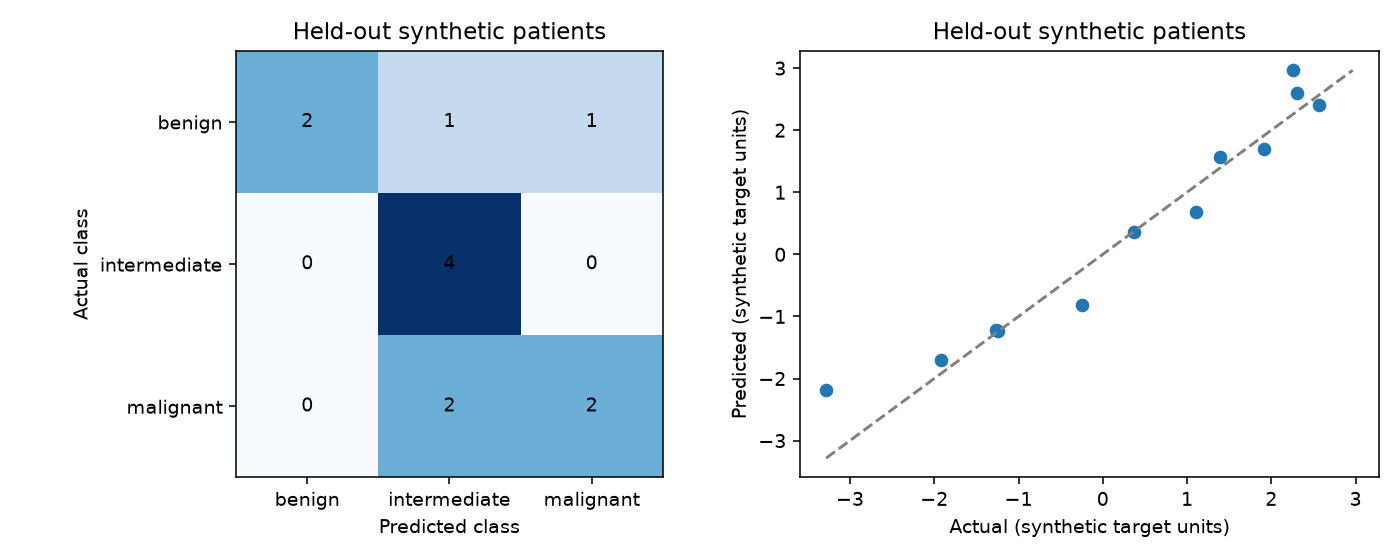

结果文件: ['multiclass', 'multiclass-metrics.csv', 'multiclass-unlabeled-predictions.csv', 'provenance.json', 'regression', 'regression-metrics.csv', 'regression-unlabeled-predictions.csv', 'task-results.png', 'tutorial-runtime.json']


In [12]:
for figure in sorted(output.glob('*.png'))[:2]:
    display(Image(filename=str(figure)))
print('结果文件:', [p.name for p in sorted(output.iterdir())])

## 换成自己的数据

保持示例的 ID、患者/切片层级与列角色约定，先替换数据读取步骤，再重新运行下游单元。先确认几何、单位、缺失状态和队列重叠；不要用测试集决定阈值或筛选参数。

重新运行全部单元会新建结果目录；只重跑保存单元可能因为文件已存在而报错，这是显式防覆盖行为。